# Interpretabilidad y comportamiento de compra
### Predicción de intención de compra en tiendas online

**Objetivo:** comprender las predicciones del modelo y analizar
qué características de navegación están asociadas con una
mayor o menor intención de compra.

Estudiaremos:

1. La importancia global de las características.


2. La dirección y magnitud de sus contribuciones.


3. Las señales predictivas independientes de PageValues.


4. Los posibles puntos de fricción en la navegación.


5. Las explicaciones de sesiones individuales.

Utilizaremos **CatBoost con 22 características**, seleccionado
tras los experimentos del notebook anterior.

La interpretación se realizará mediante SHAP, distinguiendo
entre los factores que utiliza el modelo y las posibles
causas reales del abandono.

## 1. Preparación del modelo

Reproducimos la limpieza y partición estratificada utilizadas
en los notebooks anteriores, manteniendo la semilla 42.

Entrenaremos CatBoost con las 22 características seleccionadas,
incluidas las cinco variables derivadas.

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import expit
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier, Pool

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

# --- Carga y división del dataset ---

RAIZ = Path.cwd().resolve()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

datos = pd.read_csv(
    RAIZ / "data" / "raw" / "online_shoppers_intention.csv"
)

datos = datos.drop_duplicates().reset_index(drop=True)

X = datos.drop(columns="Revenue")
y = datos["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

variables_categoricas = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

print(f"Entrenamiento: {len(X_train):,} sesiones")
print(f"Prueba reservada: {len(X_test):,} sesiones")

Entrenamiento: 9,764 sesiones
Prueba reservada: 2,441 sesiones


In [10]:
# Ingeniería de características

def crear_caracteristicas(X):
    X = X.copy()

    X["Has_PageValue"] = (X["PageValues"] > 0).astype(int)

    X["Total_Pages"] = (
        X["Administrative"]
        + X["Informational"]
        + X["ProductRelated"]
    )

    X["Total_Duration"] = (
        X["Administrative_Duration"]
        + X["Informational_Duration"]
        + X["ProductRelated_Duration"]
    )

    X["Avg_Product_Time"] = (
        X["ProductRelated_Duration"]
        / X["ProductRelated"].clip(lower=1)
    )

    X["Product_Page_Share"] = (
        X["ProductRelated"]
        / X["Total_Pages"].clip(lower=1)
    )

    return X


X_train_cb = crear_caracteristicas(X_train)

for columna in variables_categoricas:
    X_train_cb[columna] = X_train_cb[columna].astype(str)

print(f"Características utilizadas: {X_train_cb.shape[1]}")

Características utilizadas: 22


### 1.1. Entrenamiento de CatBoost

Reconstruimos el modelo con los hiperparámetros seleccionados
tras la búsqueda aleatoria y su refinamiento:

- iterations = 300
- depth = 8
- learning_rate = 0.02
- l2_leaf_reg = 1

No aplicamos ponderación de clases ni sobremuestreo, dado que
los experimentos anteriores no mostraron mejoras relevantes.

In [12]:
# CatBoost seleccionado

modelo_cb = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.02,
    l2_leaf_reg=1,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

modelo_cb.fit(
    X_train_cb,
    y_train,
    cat_features=variables_categoricas
)

print("CatBoost entrenado correctamente.")
print(f"Características: {len(modelo_cb.feature_names_)}")

CatBoost entrenado correctamente.
Características: 22


## 2. Interpretabilidad mediante SHAP

### 2.1. Cálculo de valores SHAP

Utilizamos **SHAP (SHapley Additive exPlanations)** para
descomponer las predicciones del modelo en contribuciones
individuales de las características.

Para cada sesión, la predicción se expresa como:

$$
f(x) = \phi_0 + \sum_{j=1}^{p}\phi_j(x)
$$

Donde:

- $\phi_0$ representa el valor base de la predicción.
- $\phi_j(x)$ es la contribución de cada característica.
- Una contribución positiva aumenta la puntuación de compra
  respecto al valor base; una negativa la reduce.

En CatBoost binario, estas contribuciones se expresan en
**log-odds**, no directamente en porcentajes de probabilidad.

Calcularemos los valores SHAP sobre una muestra reproducible
de 1.000 sesiones de entrenamiento, suficiente para realizar
un análisis exploratorio sin procesar todo el dataset.

Posteriormente, mediremos la importancia global mediante la
media del valor absoluto de las contribuciones.

In [19]:
# Muestra reproducible de sesiones de entrenamiento
muestra_shap = X_train_cb.sample(
    n=1000,
    random_state=RANDOM_STATE
)

pool_shap = Pool(
    muestra_shap,
    cat_features=variables_categoricas
)

# Contribuciones SHAP y valor base
valores_shap = modelo_cb.get_feature_importance(
    data=pool_shap,
    type="ShapValues"
)

contribuciones = pd.DataFrame(
    valores_shap[:, :-1],
    index=muestra_shap.index,
    columns=muestra_shap.columns
)

valores_base = valores_shap[:, -1]

# Importancia global: media de las contribuciones absolutas
importancia_shap = (
    contribuciones.abs()
    .mean()
    .sort_values(ascending=False)
)

print(f"Sesiones analizadas: {len(muestra_shap):,}")
print(f"Características explicadas: {contribuciones.shape[1]}")
print(f"Dimensiones SHAP: {valores_shap.shape}")

# Comprobar que SHAP reconstruye las predicciones
predicciones_raw = modelo_cb.predict(
    pool_shap,
    prediction_type="RawFormulaVal"
).ravel()

reconstruccion = (
    valores_base + contribuciones.sum(axis=1).to_numpy()
)

error_maximo = np.max(
    np.abs(predicciones_raw - reconstruccion)
)

print(f"Error máximo de reconstrucción: {error_maximo:.2e}")

assert np.allclose(
    predicciones_raw,
    reconstruccion,
    atol=1e-5
), "Las contribuciones SHAP no reconstruyen las predicciones."

Sesiones analizadas: 1,000
Características explicadas: 22
Dimensiones SHAP: (1000, 23)
Error máximo de reconstrucción: 1.07e-14


### 2.2. Importancia global de las características

Calculamos la importancia global de cada variable mediante
la media del valor absoluto de sus contribuciones SHAP.

Esta medida permite identificar qué características tienen
mayor influencia sobre las predicciones del modelo.

Representamos las 15 variables más importantes, ordenadas
de menor a mayor contribución media.

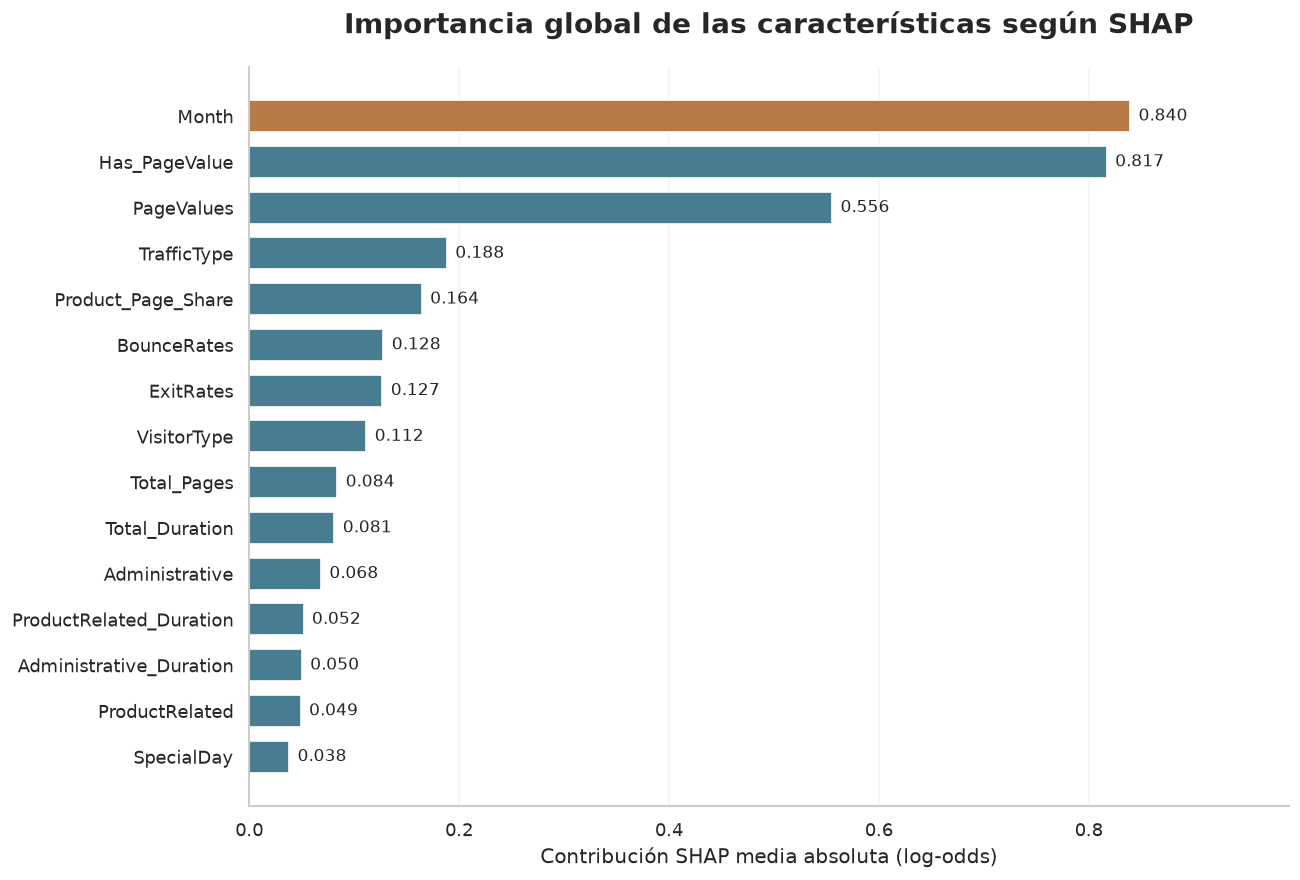

In [20]:
top_importancia = importancia_shap.head(15).sort_values()

fig, ax = plt.subplots(figsize=(11, 7.5))

colores = [
    "#B77946" if variable == importancia_shap.index[0]
    else "#487D91"
    for variable in top_importancia.index
]

barras = ax.barh(
    top_importancia.index,
    top_importancia.values,
    color=colores,
    height=0.7
)

ax.bar_label(
    barras,
    fmt="%.3f",
    padding=5,
    fontsize=10
)

ax.set_xlim(0, top_importancia.max() * 1.18)

ax.set_title(
    "Importancia global de las características según SHAP",
    fontsize=17,
    pad=20
)

ax.set_xlabel(
    "Contribución SHAP media absoluta (log-odds)"
)
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Interpretación**

- **Month (0,840)** es la característica más influyente, lo
  que sugiere que la estacionalidad desempeña un papel
  importante en las predicciones del modelo.


- **Has_PageValue (0,817) y PageValues (0,556)** destacan
  conjuntamente, en consonancia con la fuerte dependencia
  de esta información observada en el notebook 03.


- **TrafficType (0,188)** y variables de navegación como
  Product_Page_Share, BounceRates y ExitRates también
  contribuyen a las predicciones, aunque en menor medida.

  
- Varias características derivadas aparecen entre las más
  influyentes, especialmente Product_Page_Share (0,164).

## 3. Dirección de las contribuciones SHAP

### 3.1. Distribución de las contribuciones

Representamos las contribuciones SHAP de las 13 características
más importantes para las 1.000 sesiones analizadas.

Cada punto corresponde a una sesión:

- **Posición horizontal:** contribución a la predicción.
  Los valores positivos aumentan la puntuación de compra y
  los negativos la reducen.
- **Color:** valor bajo (azul) o alto (rojo) de las
  características numéricas.
- **Gris:** características categóricas, cuyos valores no
  tienen necesariamente un orden cuantitativo.

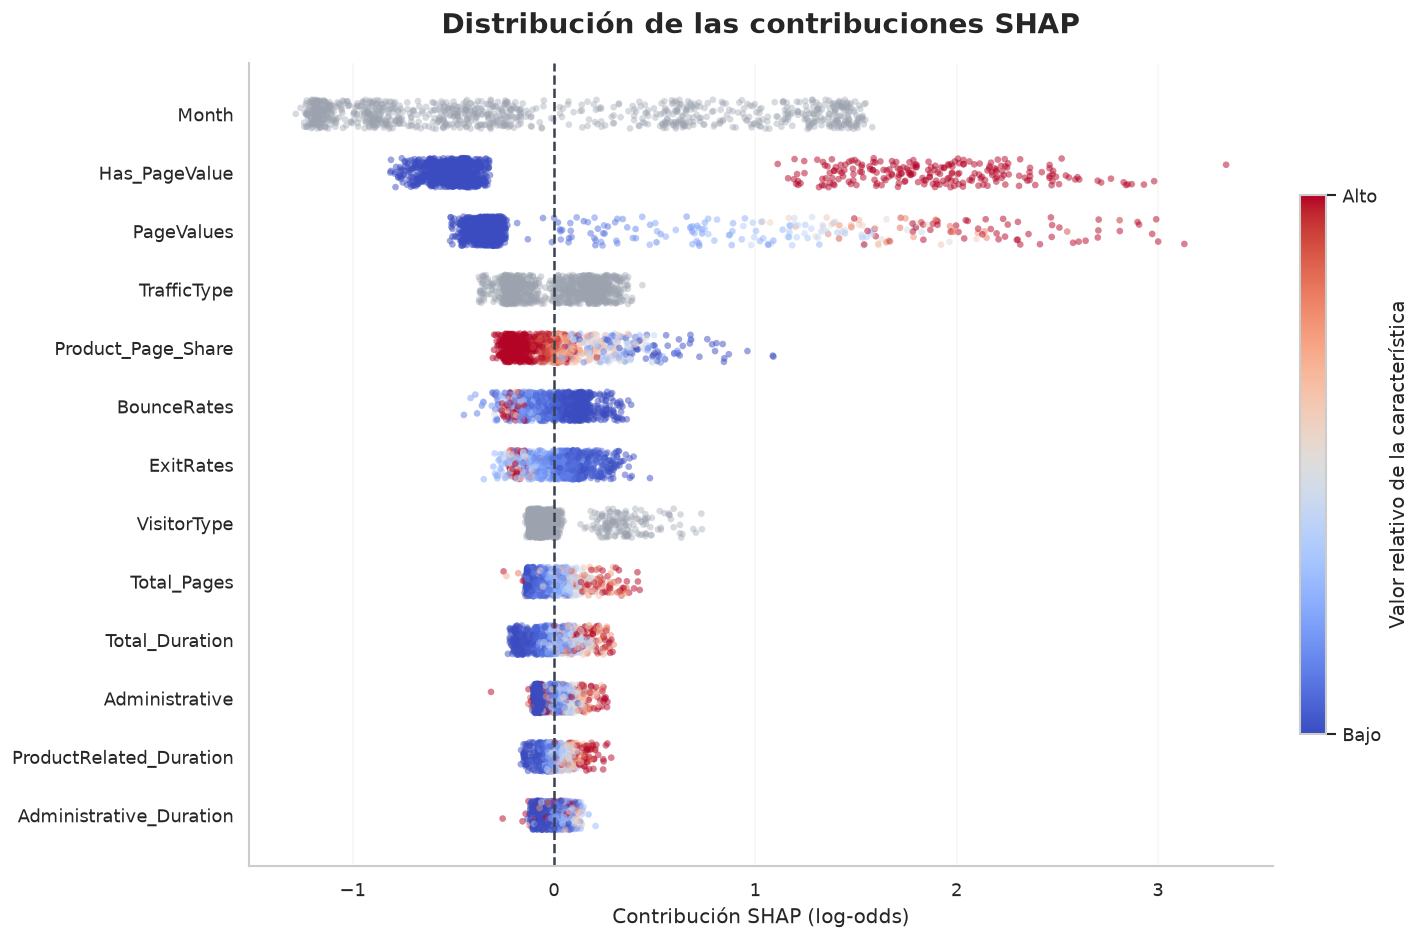

In [21]:
top_variables = importancia_shap.head(13).index[::-1]
rng = np.random.default_rng(RANDOM_STATE)

fig, ax = plt.subplots(figsize=(12, 8))

for i, variable in enumerate(top_variables):

    shap_vals = contribuciones[variable].to_numpy()
    posiciones = i + rng.uniform(-0.25, 0.25, len(shap_vals))

    if variable in variables_categoricas:
        ax.scatter(
            shap_vals, posiciones,
            color="#9CA3AF",
            s=16, alpha=0.4,
            edgecolors="none",
            rasterized=True
        )
    else:
        valores = muestra_shap[variable].astype(float).to_numpy()
        p5, p95 = np.percentile(valores, [5, 95])

        if p95 > p5:
            colores = np.clip(
                (valores - p5) / (p95 - p5), 0, 1
            )
        else:
            colores = np.full(len(valores), 0.5)

        ax.scatter(
            shap_vals, posiciones,
            c=colores,
            cmap="coolwarm",
            vmin=0, vmax=1,
            s=16, alpha=0.5,
            edgecolors="none",
            rasterized=True
        )

ax.axvline(
    0, color="#374151",
    linestyle="--", linewidth=1.5
)

ax.set_yticks(range(len(top_variables)))
ax.set_yticklabels(top_variables)

ax.set_title(
    "Distribución de las contribuciones SHAP",
    fontsize=17, pad=18
)

ax.set_xlabel("Contribución SHAP (log-odds)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.15)
ax.grid(axis="y", visible=False)

escala = plt.cm.ScalarMappable(
    norm=plt.Normalize(0, 1),
    cmap="coolwarm"
)

barra = fig.colorbar(
    escala, ax=ax,
    fraction=0.025, pad=0.025
)

barra.set_ticks([0, 1])
barra.set_ticklabels(["Bajo", "Alto"])
barra.set_label("Valor relativo de la característica")

plt.tight_layout()
plt.show()

**Interpretación**

- **PageValues y Has_PageValue:** los valores positivos elevan
  claramente la predicción de compra, mientras que los valores
  nulos presentan contribuciones negativas.


- **Month:** muestra contribuciones positivas y negativas muy
  diferenciadas. Analizaremos qué meses explican este patrón.


- **BounceRates y ExitRates:** los valores elevados
  reducen la predicción de compra, mientras que los bajos
  presentan contribuciones más favorables.


- **Intensidad de navegación:** mayores valores de Total_Pages
  y Total_Duration suelen contribuir positivamente.

  
- **Product_Page_Share:** los valores altos muestran una
  contribución predominantemente negativa, un resultado que
  requiere cautela por su relación con otras variables.

Estos patrones describen las contribuciones aprendidas por
CatBoost, condicionadas por el resto de características.
No demuestran relaciones causales.

### 3.2. Influencia del mes de visita

Month es la característica con mayor importancia SHAP global.

Al tratarse de una variable categórica, analizamos por
separado la contribución media correspondiente a cada mes.

Las contribuciones positivas aumentan la puntuación de compra
respecto al valor base del modelo; las negativas la reducen.

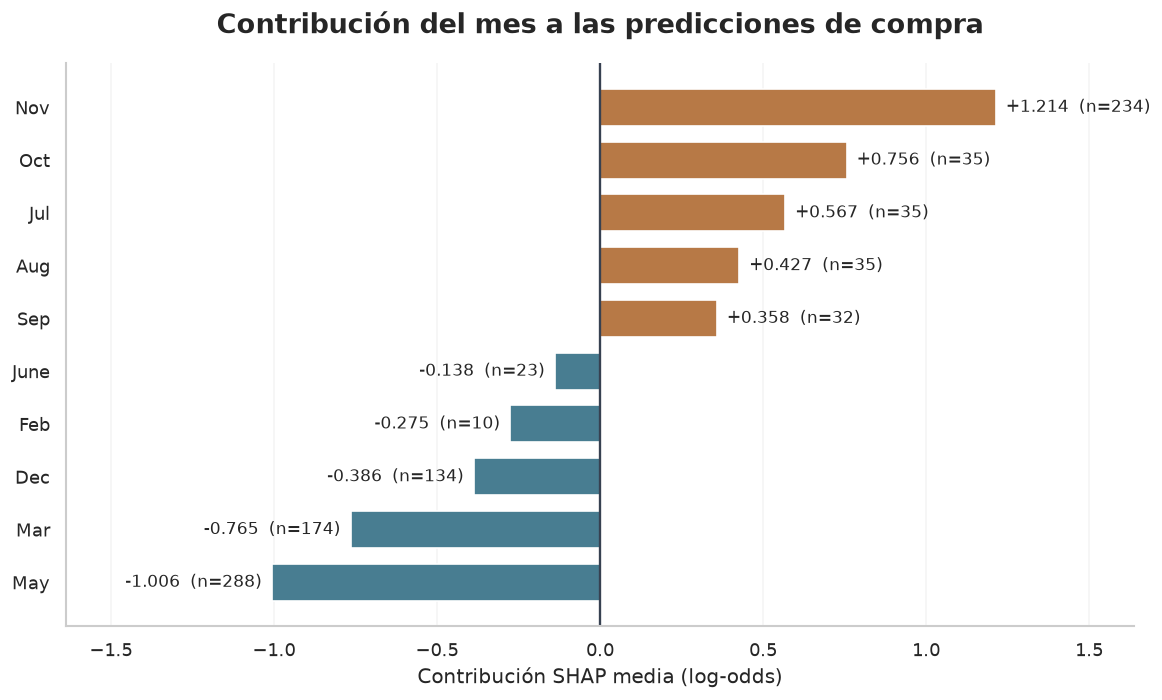

In [22]:
tabla_meses = pd.DataFrame({
    "Mes": muestra_shap["Month"],
    "SHAP": contribuciones["Month"]
})

resumen_meses = (
    tabla_meses
    .groupby("Mes")["SHAP"]
    .agg(["mean", "size"])
    .rename(columns={
        "mean": "SHAP medio",
        "size": "Sesiones"
    })
    .sort_values("SHAP medio")
)

colores = [
    "#B77946" if valor > 0 else "#487D91"
    for valor in resumen_meses["SHAP medio"]
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    resumen_meses.index,
    resumen_meses["SHAP medio"],
    color=colores,
    height=0.7
)

ax.axvline(
    0,
    color="#374151",
    linewidth=1.4
)

limite = resumen_meses["SHAP medio"].abs().max() * 1.35
ax.set_xlim(-limite, limite)

for barra, valor, n in zip(
    barras,
    resumen_meses["SHAP medio"],
    resumen_meses["Sesiones"]
):
    ax.annotate(
        f"{valor:+.3f}  (n={n})",
        (valor, barra.get_y() + barra.get_height() / 2),
        xytext=(6 if valor >= 0 else -6, 0),
        textcoords="offset points",
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=10
    )

ax.set_title(
    "Contribución del mes a las predicciones de compra",
    fontsize=16,
    pad=18
)

ax.set_xlabel("Contribución SHAP media (log-odds)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

**Interpretación**

- **Noviembre (+1,214)** presenta la mayor contribución positiva, seguido de octubre (+0,756). Esto coincide con las mayores tasas de conversión observadas en el EDA.


- **Mayo (−1,006)** y marzo (−0,765) presentan las contribuciones más negativas, asociándose con predicciones de compra inferiores.


- **Diciembre (−0,386)** también tiene una contribución negativa, a pesar de su proximidad a noviembre.


- Los resultados de meses poco representados, como febrero (10 sesiones en la muestra), tendriamos que interpretarlos con cautela.

**Conclusión:** CatBoost utiliza de forma importante la estacionalidad para diferenciar sesiones. No obstante, estas contribuciones describen patrones aprendidos del dataset, no efectos causales del mes sobre la compra.

### 3.3. Relaciones entre características numéricas y contribuciones SHAP

Analizamos cómo cambia la contribución SHAP según el valor de tres características relevantes: PageValues, ExitRates y Product_Page_Share.

Estos gráficos permiten estudiar relaciones no lineales, posibles umbrales y patrones que no se aprecian en el ranking de importancia global.

Para PageValues utilizamos una transformación logarítmica del eje horizontal debido a su elevada asimetría. Las contribuciones SHAP permanecen en su escala original de log-odds.

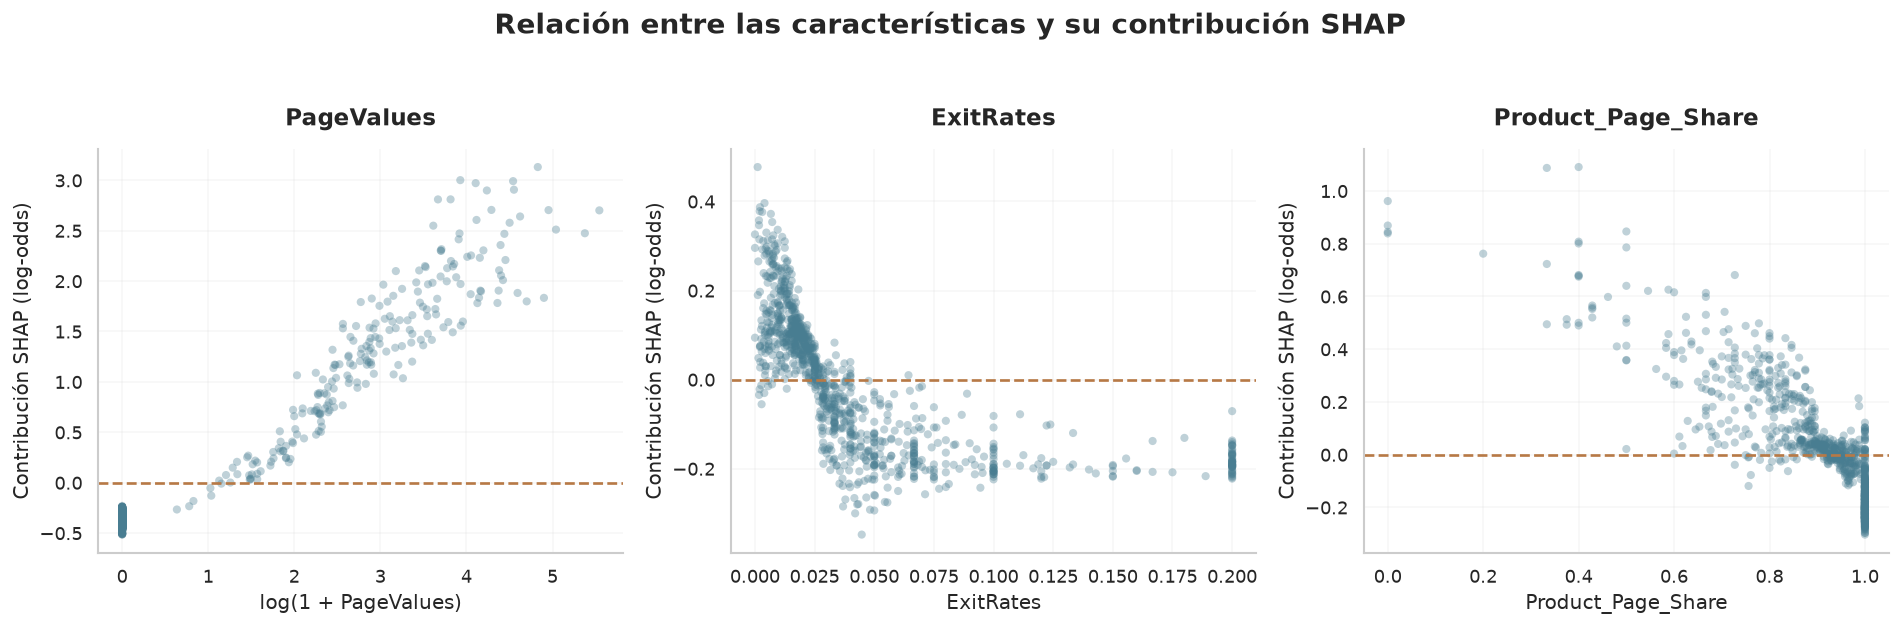

In [23]:
variables_dependencia = [
    "PageValues",
    "ExitRates",
    "Product_Page_Share"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, variable in zip(axes, variables_dependencia):

    valores = muestra_shap[variable].astype(float)
    shap_vals = contribuciones[variable]

    if variable == "PageValues":
        x = np.log1p(valores)
        etiqueta_x = "log(1 + PageValues)"
    else:
        x = valores
        etiqueta_x = variable

    ax.scatter(
        x,
        shap_vals,
        color="#487D91",
        s=24,
        alpha=0.35,
        edgecolors="none",
        rasterized=True
    )

    ax.axhline(
        0,
        color="#B77946",
        linestyle="--",
        linewidth=1.6
    )

    ax.set_title(variable, fontsize=14, pad=14)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Contribución SHAP (log-odds)")
    ax.grid(alpha=0.15)

fig.suptitle(
    "Relación entre las características y su contribución SHAP",
    fontsize=17,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **PageValues:** presenta una relación positiva muy clara. Los valores nulos reducen la puntuación de compra, mientras que las contribuciones aumentan progresivamente con su magnitud.


- **ExitRates:** las tasas bajas contribuyen positivamente, mientras que a partir de aproximadamente 0,03 predominan las contribuciones negativas. Es una señal relevante para investigar el abandono.


- **Product_Page_Share:** las proporciones intermedias muestran contribuciones frecuentemente positivas, mientras que los valores cercanos a 1 tienden a ser neutros o negativos.

**Hallazgo relevante:** una navegación concentrada exclusivamente en páginas de productos no implica necesariamente mayor intención de compra. Esto podría reflejar diferencias en los patrones de navegación, aunque no permite identificar por sí solo una causa de abandono.

## 4. Interpretabilidad sin PageValues

Los experimentos anteriores demostraron una fuerte dependencia de `PageValues`: al eliminarla, el Average Precision de CatBoost disminuyó de aproximadamente 0,757 a 0,387.

Para investigar las restantes señales de navegación, analizaremos un segundo CatBoost entrenado sin `PageValues` ni `Has_PageValue`.

Utilizaremos las 20 características restantes y la configuración seleccionada para este escenario en el notebook 03.

In [24]:
X_train_sin_page = X_train_cb.drop(
    columns=["PageValues", "Has_PageValue"]
).copy()

modelo_cb_sin_page = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.03,
    l2_leaf_reg=3,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

modelo_cb_sin_page.fit(
    X_train_sin_page,
    y_train,
    cat_features=variables_categoricas
)

# Mismas 1.000 sesiones utilizadas en el análisis anterior
muestra_sin_page = muestra_shap.drop(
    columns=["PageValues", "Has_PageValue"]
)

pool_sin_page = Pool(
    muestra_sin_page,
    cat_features=variables_categoricas
)

valores_shap_sin_page = modelo_cb_sin_page.get_feature_importance(
    data=pool_sin_page,
    type="ShapValues"
)

contribuciones_sin_page = pd.DataFrame(
    valores_shap_sin_page[:, :-1],
    index=muestra_sin_page.index,
    columns=muestra_sin_page.columns
)

importancia_sin_page = (
    contribuciones_sin_page.abs()
    .mean()
    .sort_values(ascending=False)
)

print("Modelo alternativo entrenado correctamente.")
print(f"Características: {len(modelo_cb_sin_page.feature_names_)}")

display(
    importancia_sin_page.head(10)
    .to_frame("SHAP medio absoluto")
    .style.format("{:.4f}")
)

Modelo alternativo entrenado correctamente.
Características: 20


,SHAP medio absoluto
Month,0.3750
ExitRates,0.3720
ProductRelated_Duration,0.2218
TrafficType,0.1981
Avg_Product_Time,0.1712
Product_Page_Share,0.1556
BounceRates,0.1517
Total_Duration,0.1473
VisitorType,0.1198
Administrative,0.1110


**Interpretación**

- **Month (0,3750) y ExitRates (0,3720)** son las características más influyentes del modelo sin PageValues.


- **ProductRelated_Duration (0,2218)** y **TrafficType (0,1981)** también destacan, lo que señala la relevancia de la navegación por productos y del origen del tráfico.


- Entre las variables derivadas aparecen **Avg_Product_Time (0,1712)** y **Product_Page_Share (0,1556)**, relacionadas con la intensidad y distribución de la navegación.


- **BounceRates (0,1517)** refuerza el interés por analizar los patrones de abandono.

**Siguiente paso:** estudiaremos la dirección de estas contribuciones para identificar comportamientos asociados con predicciones de compra más bajas.

### 4.2. Dirección de las contribuciones sin PageValues

Representamos las contribuciones SHAP de las 12 características más importantes del modelo alternativo.

Cada punto corresponde a una sesión. Su posición horizontal indica si la característica aumenta o reduce la puntuación de compra, mientras que el color representa el valor relativo de las variables numéricas.

Este análisis permitirá identificar patrones de navegación relevantes para investigar posibles barreras de conversión, sin confundir las contribuciones predictivas con efectos causales.

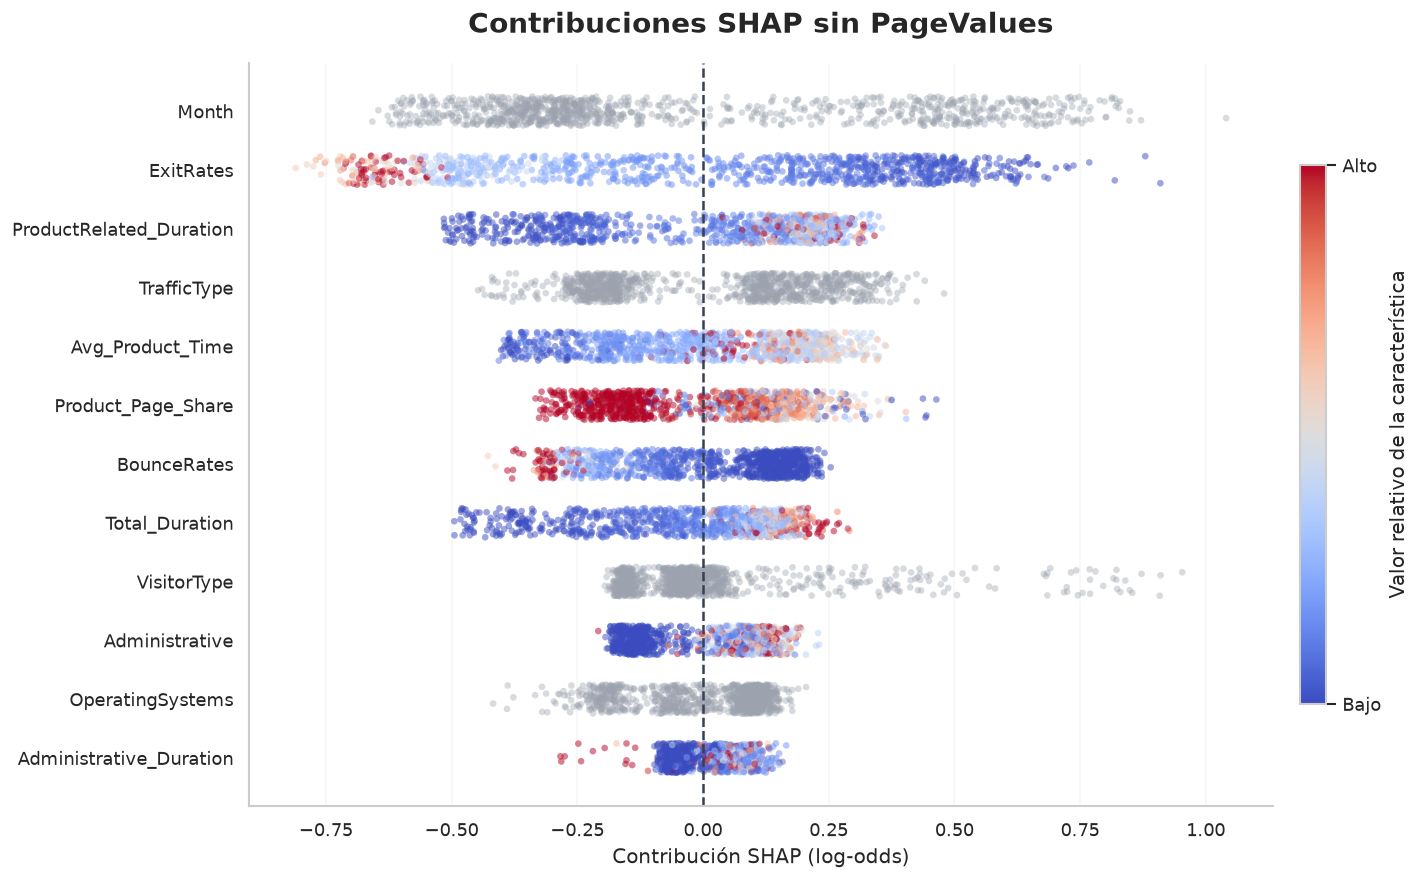

In [25]:
top_variables_sp = importancia_sin_page.head(12).index[::-1]
rng = np.random.default_rng(RANDOM_STATE)

fig, ax = plt.subplots(figsize=(12, 7.5))

for i, variable in enumerate(top_variables_sp):

    shap_vals = contribuciones_sin_page[variable].to_numpy()
    posiciones = i + rng.uniform(-0.25, 0.25, len(shap_vals))

    if variable in variables_categoricas:
        ax.scatter(
            shap_vals, posiciones,
            color="#9CA3AF",
            s=16, alpha=0.4,
            edgecolors="none",
            rasterized=True
        )
    else:
        valores = muestra_sin_page[variable].astype(float).to_numpy()
        p5, p95 = np.percentile(valores, [5, 95])

        if p95 > p5:
            colores = np.clip(
                (valores - p5) / (p95 - p5), 0, 1
            )
        else:
            colores = np.full(len(valores), 0.5)

        ax.scatter(
            shap_vals, posiciones,
            c=colores,
            cmap="coolwarm",
            vmin=0, vmax=1,
            s=16, alpha=0.5,
            edgecolors="none",
            rasterized=True
        )

ax.axvline(
    0, color="#374151",
    linestyle="--", linewidth=1.5
)

ax.set_yticks(range(len(top_variables_sp)))
ax.set_yticklabels(top_variables_sp)

ax.set_title(
    "Contribuciones SHAP sin PageValues",
    fontsize=17, pad=18
)

ax.set_xlabel("Contribución SHAP (log-odds)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.15)
ax.grid(axis="y", visible=False)

escala = plt.cm.ScalarMappable(
    norm=plt.Normalize(0, 1),
    cmap="coolwarm"
)

barra = fig.colorbar(
    escala, ax=ax,
    fraction=0.025, pad=0.025
)

barra.set_ticks([0, 1])
barra.set_ticklabels(["Bajo", "Alto"])
barra.set_label("Valor relativo de la característica")

plt.tight_layout()
plt.show()

**Interpretación**

- **ExitRates y BounceRates:** los valores elevados contribuyen negativamente a las predicciones, mientras que las tasas bajas suelen favorecerlas. Son indicadores relevantes para investigar posibles problemas de abandono.


- **ProductRelated_Duration y Avg_Product_Time:** una mayor dedicación a las páginas de productos se asocia generalmente con contribuciones positivas.


- **Total_Duration y Administrative:** los valores más elevados tienden a aumentar la puntuación de compra.


- **Product_Page_Share:** las proporciones cercanas al 100 % presentan contribuciones frecuentemente negativas, un patrón que merece investigarse.


- **Month y TrafficType:** mantienen una influencia importante, aunque sus categorías no pueden interpretarse directamente a partir de este gráfico.

**Conclusión:** incluso sin PageValues, el modelo reconoce patrones relacionados con la permanencia, la navegación por productos y el abandono. Estas señales permiten formular hipótesis sobre posibles barreras de conversión, pero no demuestran sus causas.

## 5. Análisis de posibles barreras de conversión

Las explicaciones SHAP han identificado distintas señales de navegación asociadas con las predicciones de compra.

Para contrastarlas con el comportamiento observado, analizaremos la **tasa real de conversión** según los valores de tres indicadores: ExitRates, ProductRelated_Duration y Product_Page_Share.

Dividiremos las dos primeras variables en cuartiles. Para Product_Page_Share utilizaremos intervalos específicos que permitan distinguir las sesiones dedicadas exclusivamente a páginas de productos.

Este análisis ayudará a identificar patrones que podrían revelar puntos de fricción comercial.

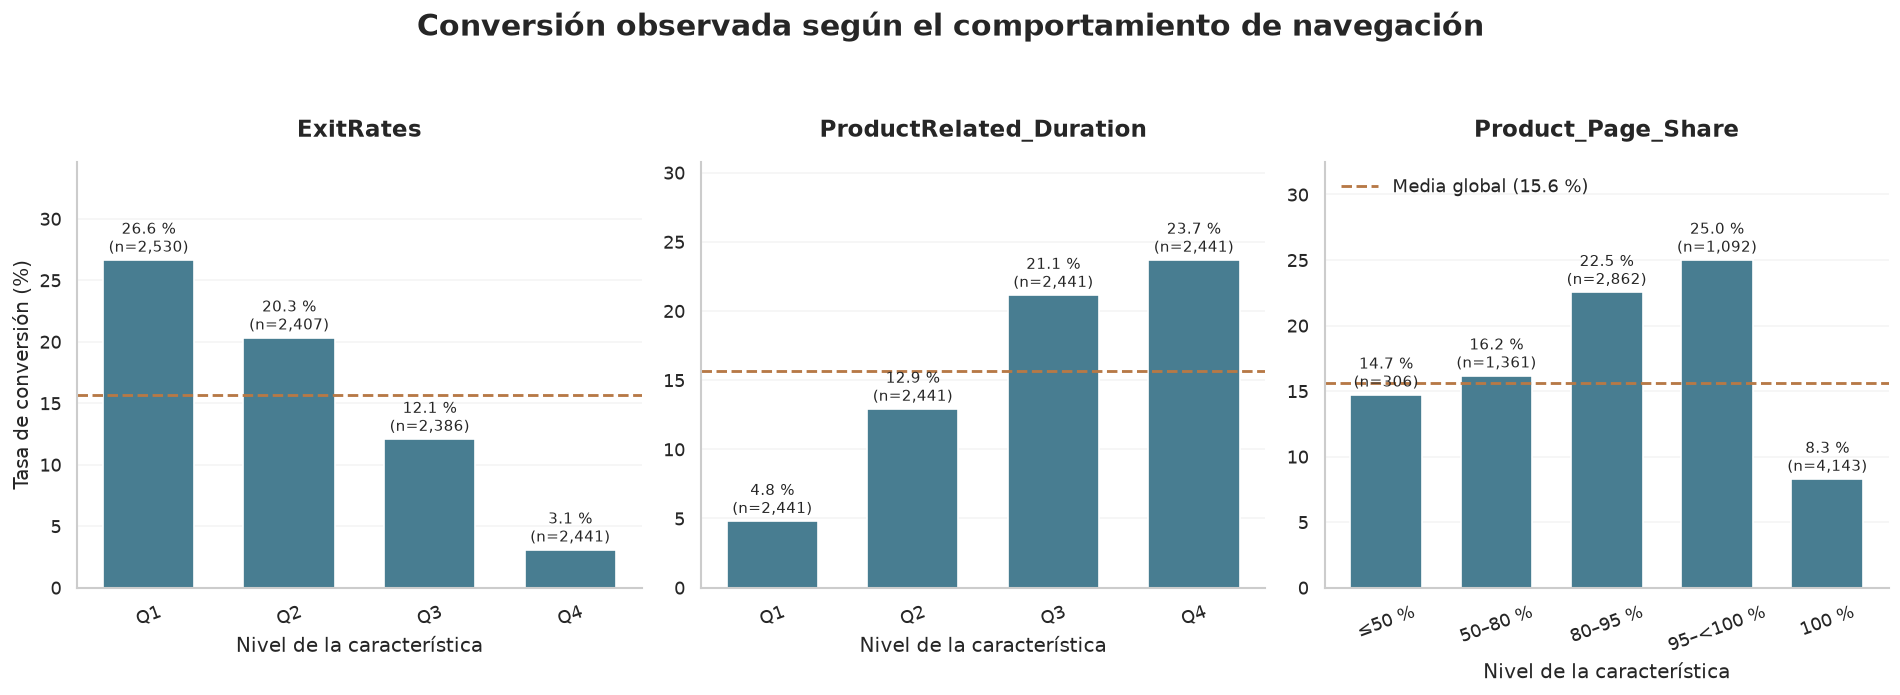

,Variable,Grupo,Intervalo,Sesiones,Conversión (%)
0,ExitRates,Q1,"(-0.001, 0.0143]","2,530",26.6
1,ExitRates,Q2,"(0.0143, 0.025]","2,407",20.3
2,ExitRates,Q3,"(0.025, 0.0492]","2,386",12.1
3,ExitRates,Q4,"(0.0492, 0.2]","2,441",3.1
4,ProductRelated_Duration,Q1,"(-0.001, 193.467]","2,441",4.8
5,ProductRelated_Duration,Q2,"(193.467, 617.0]","2,441",12.9
6,ProductRelated_Duration,Q3,"(617.0, 1483.65]","2,441",21.1
7,ProductRelated_Duration,Q4,"(1483.65, 63973.522]","2,441",23.7
8,Product_Page_Share,≤50 %,≤50 %,306,14.7
9,Product_Page_Share,50–80 %,50–80 %,"1,361",16.2


In [26]:
grupos_analisis = {
    "ExitRates": pd.qcut(
        X_train_cb["ExitRates"], q=4, duplicates="drop"
    ),
    "ProductRelated_Duration": pd.qcut(
        X_train_cb["ProductRelated_Duration"],
        q=4,
        duplicates="drop"
    ),
    "Product_Page_Share": pd.cut(
        X_train_cb["Product_Page_Share"],
        bins=[-0.001, 0.50, 0.80, 0.95, 0.999999, 1.0],
        labels=["≤50 %", "50–80 %", "80–95 %", "95–<100 %", "100 %"]
    )
}

conversion_global = y_train.mean() * 100
resultados_conversion = []

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

for ax, (variable, grupos) in zip(
    axes, grupos_analisis.items()
):

    temporal = pd.DataFrame({
        "Grupo": grupos,
        "Revenue": y_train
    })

    resumen = (
        temporal.groupby("Grupo", observed=True)["Revenue"]
        .agg(["mean", "size"])
        .reset_index()
    )

    resumen["Conversión (%)"] = resumen["mean"] * 100

    etiquetas = (
        resumen["Grupo"].astype(str).tolist()
        if variable == "Product_Page_Share"
        else [f"Q{i+1}" for i in range(len(resumen))]
    )

    barras = ax.bar(
        etiquetas,
        resumen["Conversión (%)"],
        color="#487D91",
        width=0.65
    )

    ax.axhline(
        conversion_global,
        color="#B77946",
        linestyle="--",
        linewidth=1.7,
        label=f"Media global ({conversion_global:.1f} %)"
    )

    for barra, tasa, n in zip(
        barras, resumen["Conversión (%)"], resumen["size"]
    ):
        ax.annotate(
            f"{tasa:.1f} %\n(n={n:,})",
            (
                barra.get_x() + barra.get_width() / 2,
                barra.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    for etiqueta, (_, fila) in zip(
        etiquetas, resumen.iterrows()
    ):
        resultados_conversion.append({
            "Variable": variable,
            "Grupo": etiqueta,
            "Intervalo": str(fila["Grupo"]),
            "Sesiones": fila["size"],
            "Conversión (%)": fila["Conversión (%)"]
        })

    ax.set_title(variable, fontsize=14, pad=15)
    ax.set_xlabel("Nivel de la característica")
    ax.set_ylim(
        0,
        max(resumen["Conversión (%)"].max(), conversion_global) * 1.3
    )
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Tasa de conversión (%)")
axes[2].legend(frameon=False, loc="upper left")

fig.suptitle(
    "Conversión observada según el comportamiento de navegación",
    fontsize=18,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()
plt.show()

tabla_conversion = pd.DataFrame(resultados_conversion)

display(
    tabla_conversion.style.format({
        "Sesiones": "{:,.0f}",
        "Conversión (%)": "{:.1f}"
    })
)

**Interpretación**

- **ExitRates:** la conversión disminuye progresivamente del **26,6 % al 3,1 %** entre el primer y el último cuartil. Es la señal más clara de abandono entre las analizadas.


- **ProductRelated_Duration:** las sesiones con mayor tiempo de navegación por productos presentan tasas de compra superiores, desde el **4,8 % hasta el 23,7 %**.


- **Product_Page_Share:** la conversión aumenta hasta el **25,0 %** cuando los productos representan entre el 95 % y el 100 % de las páginas visitadas, pero cae al **8,3 %** cuando representan exactamente el 100 %.

**Hallazgo principal:** las sesiones dedicadas exclusivamente a páginas de productos convierten mucho menos que aquellas que también incluyen otros tipos de páginas. Esta diferencia la investigaremos antes de interpretarla como una posible barrera de compra.

### 5.3. Navegación exclusivamente por productos

La tasa de conversión cae notablemente cuando todas las páginas visitadas corresponden a productos.

Sin embargo, esta diferencia podría estar relacionada con la duración o profundidad de la sesión, y no necesariamente con el tipo de páginas visitadas.

Para investigarlo, comparamos las tasas de conversión de las sesiones con una proporción de páginas de productos entre el 80 % y menos del 100 %, frente a las que alcanzan exactamente el 100 %, distinguiendo tres niveles de actividad según el número de páginas visitadas.

In [27]:
datos_share = X_train_cb.loc[
    X_train_cb["Product_Page_Share"] >= 0.80,
    ["Product_Page_Share", "Total_Pages"]
].copy()

datos_share["Revenue"] = y_train.loc[datos_share.index]

datos_share["Tipo de navegación"] = np.where(
    datos_share["Product_Page_Share"] == 1,
    "100 % productos",
    "80–<100 % productos"
)

datos_share["Actividad"] = pd.cut(
    datos_share["Total_Pages"],
    bins=[0, 5, 20, np.inf],
    labels=["1–5 páginas", "6–20 páginas", ">20 páginas"],
    include_lowest=True
)

resumen_share = (
    datos_share
    .groupby(
        ["Actividad", "Tipo de navegación"],
        observed=True
    )["Revenue"]
    .agg(Sesiones="size", Conversion="mean")
    .reset_index()
)

resumen_share["Conversión (%)"] = (
    resumen_share["Conversion"] * 100
)

display(
    resumen_share[
        ["Actividad", "Tipo de navegación",
         "Sesiones", "Conversión (%)"]
    ].style.format({
        "Sesiones": "{:,.0f}",
        "Conversión (%)": "{:.1f}"
    })
)

,Actividad,Tipo de navegación,Sesiones,Conversión (%)
0,1–5 páginas,100 % productos,"1,367",1.8
1,1–5 páginas,80–<100 % productos,20,10.0
2,6–20 páginas,100 % productos,"1,739",9.8
3,6–20 páginas,80–<100 % productos,793,18.0
4,>20 páginas,100 % productos,"1,037",14.2
5,>20 páginas,80–<100 % productos,"3,241",24.6


**Interpretación**

- La conversión aumenta con el número de páginas visitadas, tanto en sesiones exclusivas de productos como en sesiones mixtas.


- Sin embargo, la diferencia persiste al comparar niveles de actividad similares: **9,8 % frente a 18,0 %** entre 6–20 páginas, y **14,2 % frente a 24,6 %** cuando se superan las 20 páginas.


- La comparación de sesiones de 1–5 páginas es menos fiable por el reducido tamaño del grupo de navegación mixta (20 sesiones).

**Hallazgo:** el menor rendimiento de las sesiones dedicadas exclusivamente a productos no parece explicarse únicamente por una navegación más corta.

Este patrón sugiere investigar qué otras acciones realizan los usuarios que consultan diferentes tipos de páginas. No obstante, los datos agregados no permiten identificar las etapas exactas de abandono ni establecer relaciones causales.

**Posible explicación**

Una hipótesis es que las sesiones dedicadas exclusivamente a productos correspondan con mayor frecuencia a usuarios que exploran o comparan artículos sin intención inmediata de compra. En cambio, visitar también páginas administrativas o informativas podría reflejar una fase más avanzada del proceso de compra.

No obstante, desconocemos las páginas concretas y el orden de navegación. Por tanto, esta interpretación es una hipótesis que requeriría datos de navegación más detallados para contrastarse.

## 6. Explicaciones individuales mediante SHAP

### 6.1. Selección de sesiones

Las explicaciones globales permiten identificar patrones generales, pero cada predicción depende de una combinación particular de características.

Seleccionaremos dos sesiones del conjunto de entrenamiento, una compradora y otra no compradora, con probabilidades estimadas próximas a la mediana de sus respectivos grupos.

In [28]:
probabilidades_muestra = pd.Series(
    modelo_cb.predict_proba(pool_shap)[:, 1],
    index=muestra_shap.index
)

revenue_muestra = y_train.loc[muestra_shap.index]

# Seleccionar una sesión próxima a la mediana de cada clase
indices_ejemplo = {}

for nombre, clase in [
    ("Compradora", 1),
    ("No compradora", 0)
]:
    candidatas = probabilidades_muestra[
        revenue_muestra == clase
    ]

    indice = (
        candidatas - candidatas.median()
    ).abs().idxmin()

    indices_ejemplo[nombre] = indice

# Resumen de las dos sesiones
tabla_ejemplos = muestra_shap.loc[
    list(indices_ejemplo.values()),
    [
        "Month",
        "PageValues",
        "ExitRates",
        "ProductRelated_Duration",
        "Product_Page_Share"
    ]
].copy()

tabla_ejemplos.insert(
    0,
    "Probabilidad estimada",
    probabilidades_muestra.loc[tabla_ejemplos.index]
)

tabla_ejemplos.insert(
    0,
    "Compra real",
    revenue_muestra.loc[tabla_ejemplos.index]
)

tabla_ejemplos.index = list(indices_ejemplo.keys())

display(
    tabla_ejemplos.style.format({
        "Probabilidad estimada": "{:.1%}",
        "PageValues": "{:.2f}",
        "ExitRates": "{:.3f}",
        "ProductRelated_Duration": "{:.1f}",
        "Product_Page_Share": "{:.1%}"
    })
)

,Compra real,Probabilidad estimada,Month,PageValues,ExitRates,ProductRelated_Duration,Product_Page_Share
Compradora,1,70.0%,May,32.99,0.017,724.1,93.3%
No compradora,0,1.3%,Dec,0.00,0.022,677.7,100.0%


### 6.2. Contribuciones SHAP de las sesiones seleccionadas

Analizamos qué características aumentan o reducen la
predicción de compra en las dos sesiones anteriores.

Representamos las ocho contribuciones de mayor magnitud
y agrupamos las restantes para facilitar la lectura.

- **Contribuciones positivas:** aumentan la puntuación
  de compra respecto al valor base.

  
- **Contribuciones negativas:** la reducen.

Las contribuciones se expresan en log-odds. La probabilidad
estimada resulta de aplicar la función logística a la suma
del valor base y todas las contribuciones.

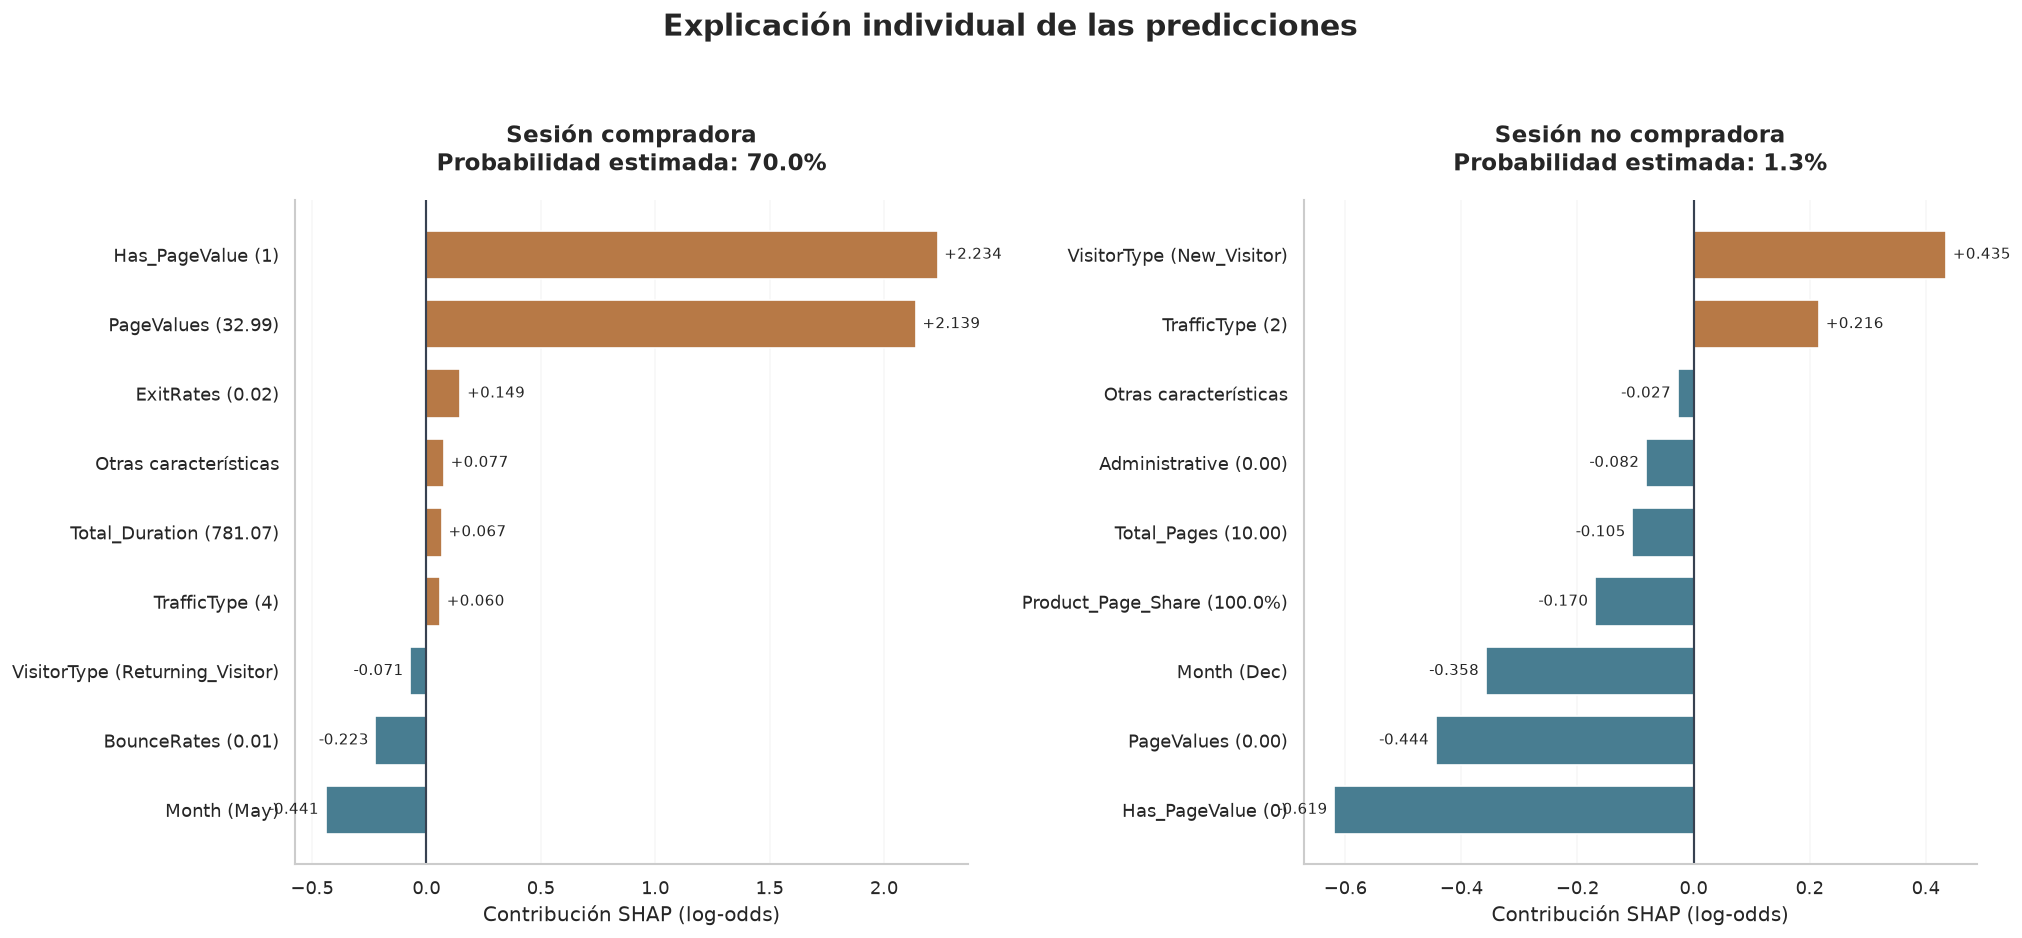

In [29]:
ejemplos = [
    ("Compradora", indices_ejemplo["Compradora"]),
    ("No compradora", indices_ejemplo["No compradora"])
]

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

for ax, (nombre, indice) in zip(axes, ejemplos):

    shap_sesion = contribuciones.loc[indice]

    # Seleccionar las ocho contribuciones más relevantes
    principales = shap_sesion.abs().nlargest(8).index
    aportaciones = shap_sesion.loc[principales].copy()

    # Agrupar todas las contribuciones restantes
    aportaciones["Otras características"] = (
        shap_sesion.drop(principales).sum()
    )

    aportaciones = aportaciones.sort_values()

    # Etiquetas con el valor observado de cada característica
    etiquetas = []

    for variable in aportaciones.index:

        if variable == "Otras características":
            etiquetas.append(variable)
            continue

        valor = muestra_shap.loc[indice, variable]

        if variable in variables_categoricas:
            valor_texto = str(valor)
        elif variable == "Has_PageValue":
            valor_texto = str(int(valor))
        elif variable == "Product_Page_Share":
            valor_texto = f"{valor:.1%}"
        else:
            valor_texto = f"{valor:.2f}"

        etiquetas.append(f"{variable} ({valor_texto})")

    colores = [
        "#B77946" if valor >= 0 else "#487D91"
        for valor in aportaciones
    ]

    barras = ax.barh(
        etiquetas,
        aportaciones.values,
        color=colores,
        height=0.7
    )

    ax.bar_label(
        barras,
        fmt="%+.3f",
        padding=4,
        fontsize=9
    )

    ax.axvline(
        0,
        color="#374151",
        linewidth=1.3
    )

    probabilidad = probabilidades_muestra.loc[indice]

    ax.set_title(
        f"Sesión {nombre.lower()}\n"
        f"Probabilidad estimada: {probabilidad:.1%}",
        fontsize=14,
        pad=18
    )

    ax.set_xlabel("Contribución SHAP (log-odds)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Explicación individual de las predicciones",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Sesión compradora (70,0 %):** las mayores contribuciones positivas proceden de `Has_PageValue` (+2,234) y `PageValues` (+2,139). Estas compensan las contribuciones negativas de mayo (−0,441) y `BounceRates` (−0,223).


- **Sesión no compradora (1,3 %):** la ausencia de valor de página aporta las principales contribuciones negativas. También destacan diciembre (−0,358) y la navegación exclusivamente por productos (−0,170).


- Aunque la segunda sesión presenta contribuciones positivas de `VisitorType` y `TrafficType`, no son suficientes para compensar las negativas.

**Conclusión:** las explicaciones individuales muestran cómo el modelo combina diferentes señales para estimar la probabilidad de compra. También refuerzan la fuerte dependencia de `PageValues`, aunque sus contribuciones y las de `Has_PageValue` están relacionadas y no constituyen evidencias independientes.

### 6.3. Reconstrucción de las probabilidades

Comprobamos que las contribuciones SHAP reconstruyen las
predicciones de las dos sesiones analizadas.

Sumamos el valor base y las contribuciones de las 22
características en escala log-odds. Después aplicamos
la función logística para obtener la probabilidad de compra.

Esta comprobación verifica la coherencia matemática de las
explicaciones individuales con las predicciones del modelo.

In [30]:
from scipy.special import expit


resultados_locales = []

for nombre, indice in indices_ejemplo.items():

    posicion = muestra_shap.index.get_loc(indice)

    valor_base = valores_base[posicion]
    suma_shap = contribuciones.loc[indice].sum()

    probabilidad_reconstruida = expit(
        valor_base + suma_shap
    )

    probabilidad_modelo = probabilidades_muestra.loc[indice]

    resultados_locales.append({
        "Sesión": nombre,
        "Valor base": valor_base,
        "Suma SHAP": suma_shap,
        "Probabilidad SHAP": probabilidad_reconstruida,
        "Probabilidad CatBoost": probabilidad_modelo,
        "Error absoluto": abs(
            probabilidad_reconstruida - probabilidad_modelo
        )
    })

tabla_locales = pd.DataFrame(resultados_locales)

display(
    tabla_locales.style.format({
        "Valor base": "{:.3f}",
        "Suma SHAP": "{:+.3f}",
        "Probabilidad SHAP": "{:.2%}",
        "Probabilidad CatBoost": "{:.2%}",
        "Error absoluto": "{:.2e}"
    })
)

,Sesión,Valor base,Suma SHAP,Probabilidad SHAP,Probabilidad CatBoost,Error absoluto
0,Compradora,-3.144,+3.992,70.01%,70.01%,5.55e-16
1,No compradora,-3.144,-1.153,1.34%,1.34%,0.00e+00


## 7. Conclusiones y posibles recomendaciones

El análisis SHAP ha permitido identificar las características que más influyen en las predicciones de CatBoost y contrastar algunas de sus relaciones con las tasas de conversión observadas.

### 7.1. Principales hallazgos

- **Estacionalidad:** `Month` presenta la mayor importancia SHAP global. Noviembre y octubre contribuyen positivamente a las predicciones, mientras que mayo y marzo muestran contribuciones negativas.


- **Dependencia de PageValues:** `PageValues` y `Has_PageValue` son determinantes para el modelo principal. Su elevada influencia refuerza la necesidad de justificar la disponibilidad temporal de esta información antes de utilizarla en una aplicación real.


- **Abandono y permanencia:** sin `PageValues`, destacan `ExitRates`, `ProductRelated_Duration` y `BounceRates`. La conversión disminuye del **26,6 % al 3,1 %** entre los extremos de `ExitRates`, mientras que aumenta del **4,8 % al 23,7 %** según el tiempo dedicado a productos.


- **Tipo de navegación:** las sesiones dedicadas exclusivamente a productos presentan una conversión del **8,3 %**, inferior a la de aquellas que también visitan otros tipos de páginas. Esta diferencia persiste parcialmente al comparar sesiones con una profundidad de navegación similar.

### 7.2. Posibles implicaciones comerciales

Los resultados sugieren tres líneas de investigación para una tienda online:

1. **Investigar el abandono:** identificar las páginas o etapas donde se producen salidas frecuentes y comprobar si existen problemas de usabilidad, información insuficiente o dificultades para continuar la compra.


2. **Analizar la experiencia de consulta de productos:** estudiar qué características distinguen las sesiones exploratorias de aquellas con mayor intención de compra, prestando atención a la información disponible y a la navegación entre secciones.


3. **Considerar la estacionalidad:** adaptar el análisis y las estrategias comerciales a los distintos periodos del año, comprobando si los patrones observados se mantienen en otros conjuntos de datos.

Estas propuestas constituyen **hipótesis de mejora**, no soluciones cuya eficacia haya quedado demostrada. Sería necesario contrastarlas mediante datos de navegación más detallados y, cuando corresponda, pruebas A/B.

### 7.3. Limitaciones

- SHAP explica las predicciones del modelo, pero no establece relaciones causales.


- Los registros agregados por sesión no permiten conocer el orden de las páginas visitadas ni identificar el punto exacto donde se abandona la compra.


- El modelo depende considerablemente de `PageValues`, cuya disponibilidad durante una sesión real debe justificarse.


- La interpretabilidad se ha estudiado sobre datos de entrenamiento. La capacidad de generalización debe comprobarse mediante la evaluación final independiente.

**Conclusión:** el modelo no solo permite estimar la intención de compra, sino también detectar patrones de navegación que merecen investigación comercial. Su principal valor interpretativo consiste en orientar nuevas preguntas y posibles intervenciones, evitando confundir las asociaciones observadas con las causas reales del abandono.